# Multi-Class Benchmark Classification Pipeline — Iris Dataset

**Task:** Build and compare Logistic Regression and Decision Tree classifiers using Scikit-Learn.

This notebook completes the requested workflow:
- Load the Iris dataset with Pandas
- Explore the data and visualize feature relationships with a Seaborn pairplot
- Split the data into 80% training and 20% testing sets
- Standardize features with `StandardScaler`
- Train Logistic Regression and Decision Tree models
- Compare accuracy, precision, recall, and F1-score
- Display classification reports and confusion-matrix heatmaps
- Visualize two-feature decision boundaries

**Dataset:** [Iris CSV](https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv)

> The split is stratified so each flower class is represented proportionally in both sets. Scaling is fitted only on training data to prevent data leakage.

In [12]:
# 1. Import required libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42


## 2. Load the dataset

In [13]:
# Try the supplied CSV first. If the CSV cannot be reached, use
# Scikit-Learn's built-in copy of the same Iris benchmark dataset.
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

try:
    df = pd.read_csv(DATA_URL)
    print("Loaded Iris data from the supplied CSV.")
except Exception as error:
    print("Could not download CSV; using Scikit-Learn's built-in Iris dataset.")
    iris = load_iris(as_frame=True)
    df = iris.frame.rename(columns={
        "sepal length (cm)": "sepal_length",
        "sepal width (cm)": "sepal_width",
        "petal length (cm)": "petal_length",
        "petal width (cm)": "petal_width",
        "target": "species"
    })
    df["species"] = df["species"].map(dict(enumerate(iris.target_names)))

df.head()


Loaded Iris data from the supplied CSV.


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [14]:
# Basic dataset inspection
print("Dataset shape:", df.shape)
print("\\nColumn information:")
df.info()
print("\\nMissing values per column:")
display(df.isnull().sum())
print("\\nClass distribution:")
display(df["species"].value_counts())


Dataset shape: (150, 5)
\nColumn information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
\nMissing values per column:


,0
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


\nClass distribution:


,count
species,
setosa,50
versicolor,50
virginica,50


## 3. Exploratory Data Analysis (EDA)

,sepal_length,sepal_width,petal_length,petal_width,species
count,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,setosa
freq,NaN,NaN,NaN,NaN,50
mean,5.843333,3.057333,3.758000,1.199333,NaN
std,0.828066,0.435866,1.765298,0.762238,NaN
min,4.300000,2.000000,1.000000,0.100000,NaN
25%,5.100000,2.800000,1.600000,0.300000,NaN
50%,5.800000,3.000000,4.350000,1.300000,NaN
75%,6.400000,3.300000,5.100000,1.800000,NaN


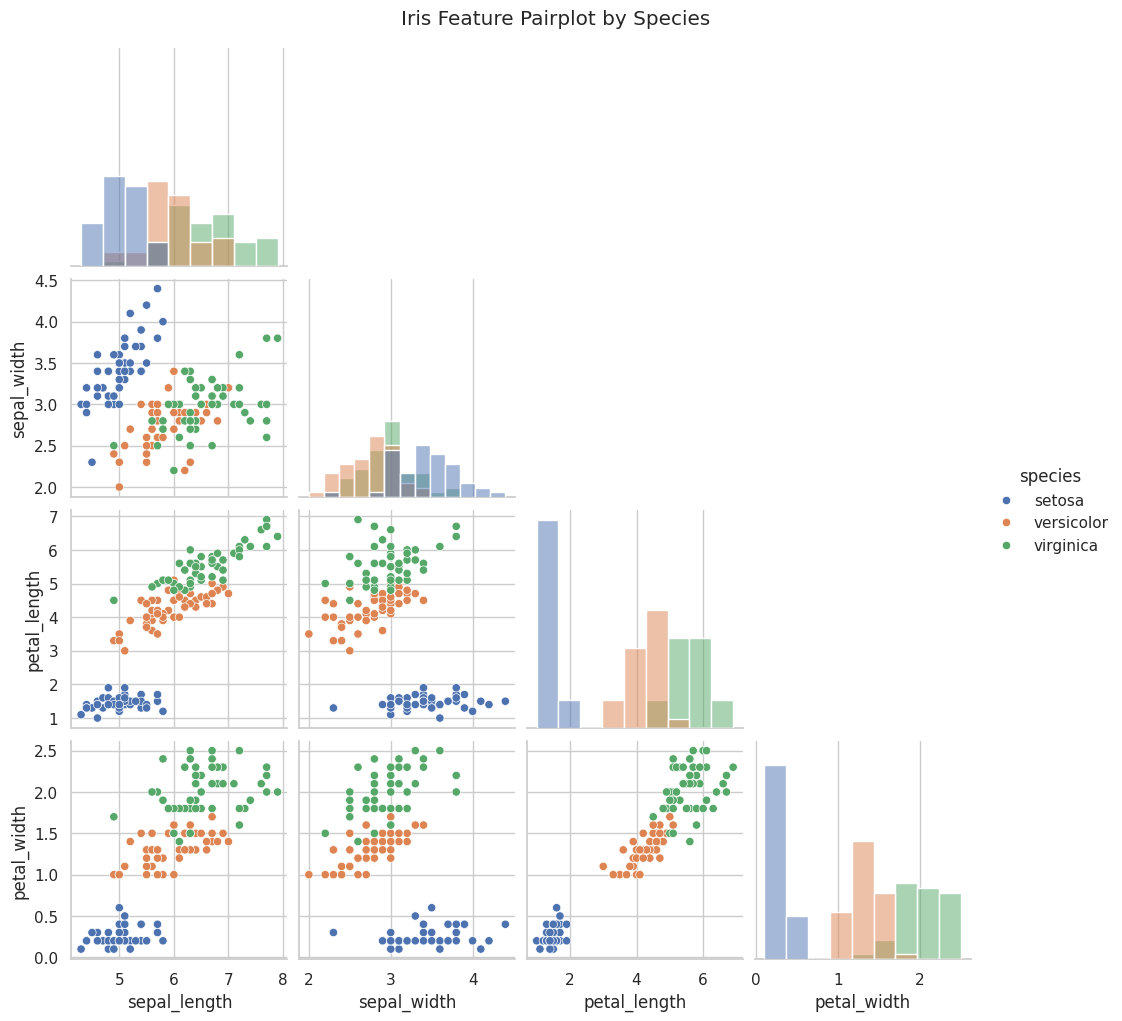

In [15]:
# Summary statistics
display(df.describe(include="all"))

# Check for missing values before modeling
if df.isnull().any().any():
    raise ValueError("The dataset contains missing values. Handle them before training.")

# Pairplot: relationships between all four measurements, colored by species
sns.pairplot(df, hue="species", diag_kind="hist", corner=True)
plt.suptitle("Iris Feature Pairplot by Species", y=1.02)
plt.show()


## 4. Prepare features and split the data

The target is `species`; the four numeric flower measurements are the input features. The test set contains 20% of the data. `stratify=y` preserves class proportions.

In [16]:
X = df.drop(columns="species")
y = df["species"]

# Ensure all input features are numeric
X = X.apply(pd.to_numeric, errors="raise")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("\\nTraining class distribution:")
display(y_train.value_counts())
print("\\nTesting class distribution:")
display(y_test.value_counts())


Training feature shape: (120, 4)
Testing feature shape: (30, 4)
\nTraining class distribution:


,count
species,
setosa,40
virginica,40
versicolor,40


\nTesting class distribution:


,count
species,
setosa,10
virginica,10
versicolor,10


## 5. Build and train the classification pipelines

Both models use a Scikit-Learn `Pipeline` containing `StandardScaler`. This ensures scaling is learned from the training data only. Standardization is particularly important for Logistic Regression; the Decision Tree is included in the same consistent pipeline for comparison.

In [17]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ])
}

for model_name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{model_name}: training complete")


Logistic Regression: training complete
Decision Tree: training complete


## 6. Evaluate and benchmark the models

In [18]:
results = []
predictions = {}

for model_name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[model_name] = y_pred

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))


,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


In [19]:
# Detailed classification reports
for model_name, y_pred in predictions.items():
    print(f"\\n{'=' * 60}\\n{model_name} — Classification Report\\n{'=' * 60}")
    print(classification_report(y_test, y_pred, zero_division=0))


\n============================================================\nLogistic Regression — Classification Report\n============================================================
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

\n============================================================\nDecision Tree — Classification Report\n============================================================
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg 

## 7. Confusion matrix heatmaps

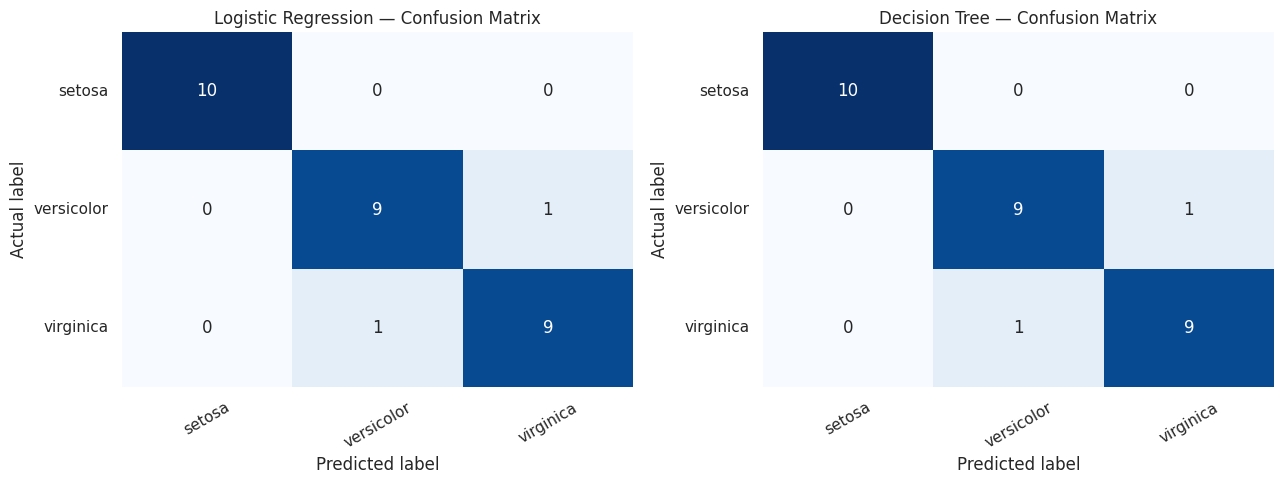

In [20]:
class_names = sorted(y.unique())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=class_names)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=class_names, yticklabels=class_names, ax=ax
    )
    ax.set_title(f"{model_name} — Confusion Matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()


## 8. Compare benchmark metrics visually

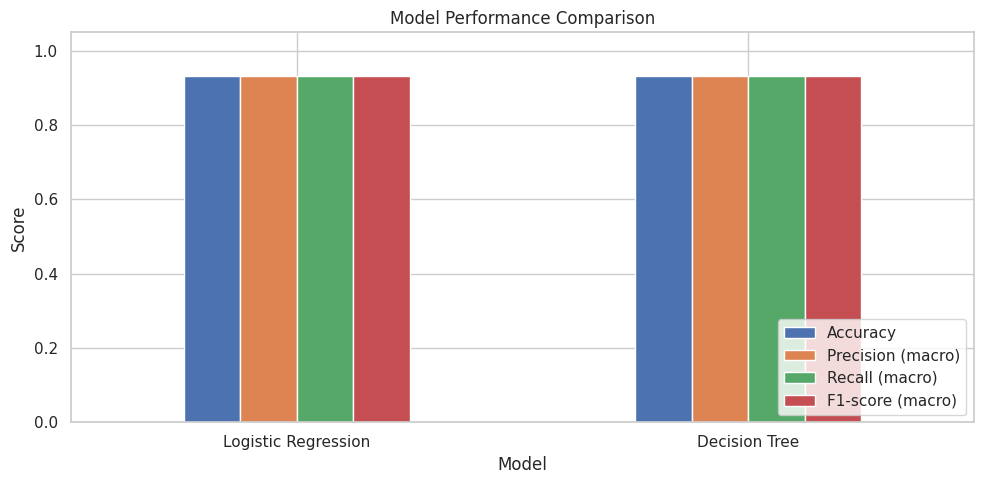

In [21]:
metrics_to_plot = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]
results_df[metrics_to_plot].plot(kind="bar", figsize=(10, 5), ylim=(0, 1.05))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


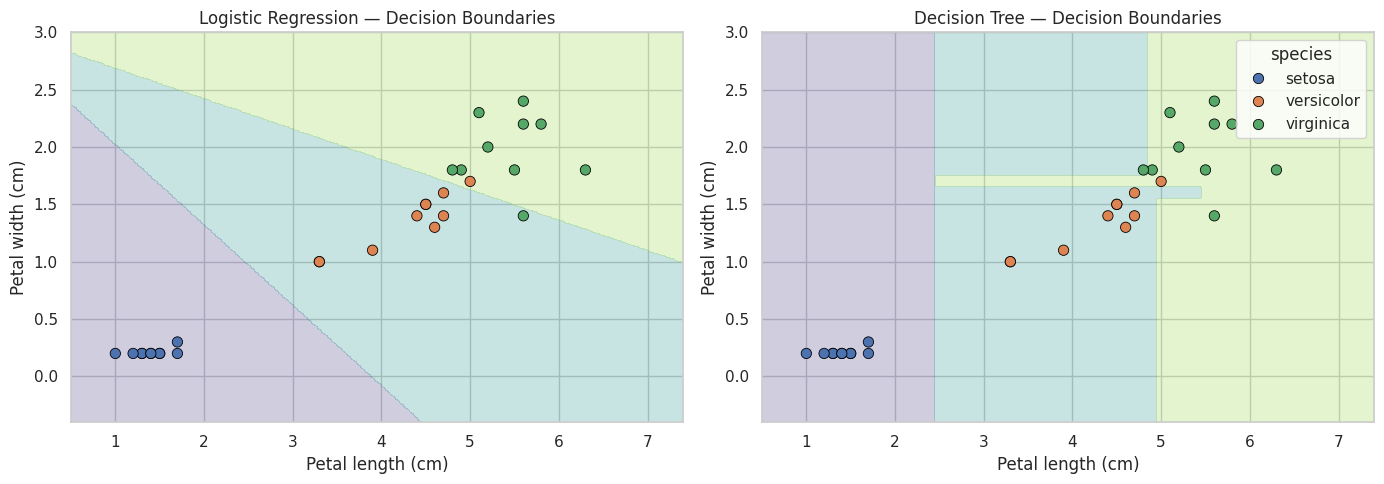

In [22]:
# Use two features so the classification regions can be drawn on a 2D plot.
boundary_features = ["petal_length", "petal_width"]
X_2d = df[boundary_features]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

boundary_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ])
}

x_min, x_max = X_2d.iloc[:, 0].min() - 0.5, X_2d.iloc[:, 0].max() + 0.5
y_min, y_max = X_2d.iloc[:, 1].min() - 0.5, X_2d.iloc[:, 1].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)
grid = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=boundary_features
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (model_name, model) in zip(axes, boundary_models.items()):
    model.fit(X2_train, y2_train)
    grid_predictions = model.predict(grid)

    # Convert class labels to integer codes for contour plotting
    class_to_code = {name: i for i, name in enumerate(class_names)}
    Z = pd.Series(grid_predictions).map(class_to_code).to_numpy().reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.25, cmap="viridis", levels=np.arange(-0.5, 3.5, 1))
    sns.scatterplot(
        x=X2_test[boundary_features[0]],
        y=X2_test[boundary_features[1]],
        hue=y2_test,
        hue_order=class_names,
        palette="deep",
        edgecolor="black",
        s=55,
        ax=ax,
        legend=(ax is axes[1])
    )
    ax.set_title(f"{model_name} — Decision Boundaries")
    ax.set_xlabel("Petal length (cm)")
    ax.set_ylabel("Petal width (cm)")

plt.tight_layout()
plt.show()
